## Exercício 8

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

# Deixa os resultados reprodutíveis
np.random.seed(42)


A função abaixo reproduz o mesmo tipo de dado em espiral usado no
TensorFlow Playground: duas espirais entrelaçadas, cada uma
representando uma classe, com um nível de ruído (noise) que desloca
aleatoriamente os pontos de sua posição ideal.


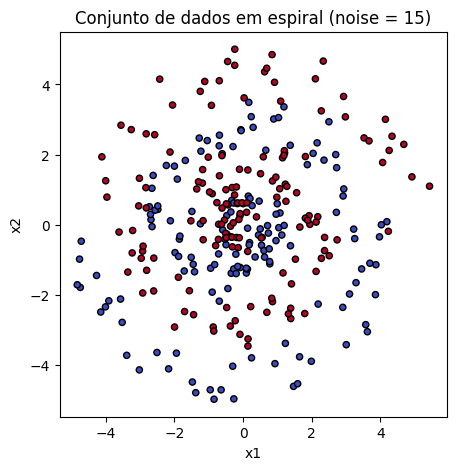

In [3]:
def gerar_espiral(n_pontos=150, noise=15):
    """Gera duas espirais entrelaçadas (classes 0 e 1).

    Parâmetros
    ----------
    n_pontos : int
        Número de pontos por classe.
    noise : float
        Nível de ruído, na mesma escala usada pelo Playground (0 a 50).
    """
    noise = noise / 100.0

    def uma_espiral(delta_t, label):
        indices = np.arange(n_pontos)
        r = indices / n_pontos * 5
        t = 1.75 * indices / n_pontos * 2 * np.pi + delta_t
        x1 = r * np.sin(t) + np.random.uniform(-1, 1, n_pontos) * noise * 5
        x2 = r * np.cos(t) + np.random.uniform(-1, 1, n_pontos) * noise * 5
        y = np.full(n_pontos, label)
        return np.column_stack([x1, x2]), y

    x_a, y_a = uma_espiral(0, 0)
    x_b, y_b = uma_espiral(np.pi, 1)

    X = np.vstack([x_a, x_b])
    y = np.concatenate([y_a, y_b])
    return X, y


X, y = gerar_espiral(n_pontos=150, noise=15)

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolor="k", s=20)
plt.title("Conjunto de dados em espiral (noise = 15)")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()


Os dados são padronizados (média 0, desvio padrão 1) e divididos
seguindo a mesma proporção usada no Playground.


In [4]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

escala = StandardScaler()
X_treino = escala.fit_transform(X_treino)
X_teste = escala.transform(X_teste)

print(f"Exemplos de treino: {len(X_treino)}")
print(f"Exemplos de teste:  {len(X_teste)}")


Exemplos de treino: 210
Exemplos de teste:  90


Para facilitar a comparação entre arquiteturas, foi criado uma função
que treina a rede, calcula a acurácia em treino/teste e desenha a
fronteira de decisão aprendida (equivalente à imagem de fundo colorida
do Playground).


In [5]:
def treinar_e_avaliar(hidden_layer_sizes, ativacao="relu", titulo=""):
    modelo = MLPClassifier(
        hidden_layer_sizes=hidden_layer_sizes,
        activation=ativacao,
        solver="adam",
        batch_size=10,
        max_iter=2000,
        random_state=42,
    )
    modelo.fit(X_treino, y_treino)

    acc_treino = modelo.score(X_treino, y_treino)
    acc_teste = modelo.score(X_teste, y_teste)

    # --- fronteira de decisão ---
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200)
    )
    grade = escala.transform(np.c_[xx.ravel(), yy.ravel()])
    Z = modelo.predict(grade).reshape(xx.shape)

    plt.figure(figsize=(5, 5))
    plt.contourf(xx, yy, Z, cmap="coolwarm", alpha=0.4)
    plt.scatter(
        X_treino[:, 0], X_treino[:, 1], c=y_treino,
        cmap="coolwarm", edgecolor="white", s=25, label="treino",
    )
    plt.scatter(
        X_teste[:, 0], X_teste[:, 1], c=y_teste,
        cmap="coolwarm", edgecolor="black", s=25, label="teste",
    )
    plt.title(f"{titulo}\nAcurácia treino={acc_treino:.2f} | teste={acc_teste:.2f}")
    plt.legend(loc="upper right", fontsize=8)
    plt.show()

    return acc_treino, acc_teste


Foi testado algumas arquiteturas diferentes para observar o efeito do tamanho da rede na capacidade de separar a espiral.


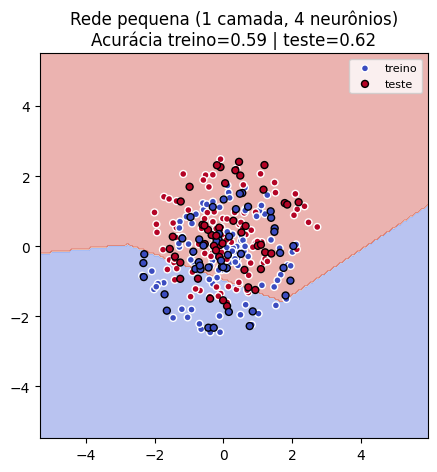

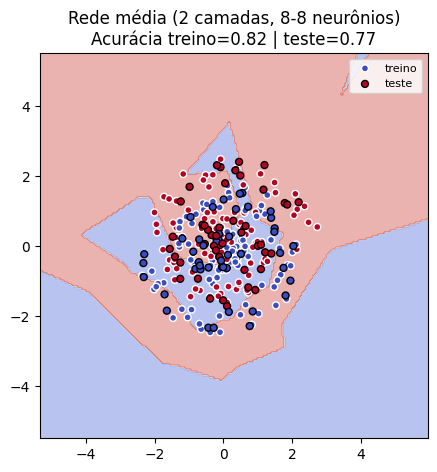

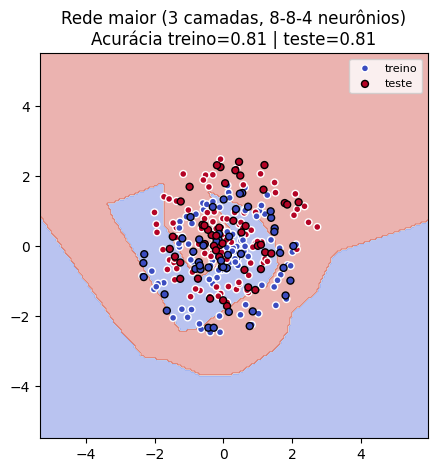

In [6]:
arquiteturas = {
    "Rede pequena (1 camada, 4 neurônios)": (4,),
    "Rede média (2 camadas, 8-8 neurônios)": (8, 8),
    "Rede maior (3 camadas, 8-8-4 neurônios)": (8, 8, 4),
}

resultados = {}
for nome, camadas in arquiteturas.items():
    acc_treino, acc_teste = treinar_e_avaliar(camadas, titulo=nome)
    resultados[nome] = (acc_treino, acc_teste)


### Resumo dos resultados

In [8]:
print(f"{'Arquitetura':40s} {'Treino':>8s} {'Teste':>8s}")
for nome, (acc_treino, acc_teste) in resultados.items():
    print(f"{nome:40s} {acc_treino:8.2f} {acc_teste:8.2f}")


Arquitetura                                Treino    Teste
Rede pequena (1 camada, 4 neurônios)         0.59     0.62
Rede média (2 camadas, 8-8 neurônios)        0.82     0.77
Rede maior (3 camadas, 8-8-4 neurônios)      0.81     0.81


A rede pequena (poucos neurônios em uma única camada) tem
  dificuldade em separar a espiral: sua fronteira de decisão é simples
  demais para acompanhar o formato curvo dos dados, resultando em
  acurácia mais baixa tanto no treino quanto no teste.

Ao aumentar o número de camadas e neurônios, a rede consegue
  representar fronteiras de decisão mais complexas e curvas,
  aproximando-se melhor do formato da espiral — o que se reflete em
  uma acurácia de teste mais alta.

Redes maiores, no entanto, também aumentam o risco de
  overfitting (decorar o ruído dos dados de treino em vez de
  aprender o padrão real), por isso é importante observar não só a
  acurácia de treino, mas principalmente a de teste.
  
Esse comportamento é o mesmo observado no TensorFlow Playground: o
  problema da espiral só é resolvido de forma satisfatória com redes
  neurais suficientemente profundas, pois um modelo linear (ou uma
  rede muito pequena) não tem capacidade de representar a
  não-linearidade do problema.
